## Polynomial Regression on Boston Housing Dataset

**In this notebook we do a comparative study of Linear Regression and Polynomial Regression accuracy on the Boston Housing Dataset**

This data was originally a part of UCI Machine Learning Repository and has been removed now. This data also ships with the scikit-learn library. 
There are 506 samples and 13 feature variables in this data-set. The objective is to predict the value of prices of the house using the given features.

The description of all the features is given below:

  **CRIM**: Per capita crime rate by town

  **ZN**: Proportion of residential land zoned for lots over 25,000 sq. ft

  **INDUS**: Proportion of non-retail business acres per town

  **CHAS**: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)

  **NOX**: Nitric oxide concentration (parts per 10 million)

  **RM**: Average number of rooms per dwelling

  **AGE**: Proportion of owner-occupied units built prior to 1940

  **DIS**: Weighted distances to five Boston employment centers

  **RAD**: Index of accessibility to radial highways

  **TAX**: Full-value property tax rate per $10,000

  **B**: 1000(Bk - 0.63)², where Bk is the proportion of [people of African American descent] by town

  **LSTAT**: Percentage of lower status of the population

  **MEDV**: Median value of owner-occupied homes in $1000s
  
  
  



I**mport the required Libraries**

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

**Load the data into pandas dataframe . Load the Boston Housing DataSet from data/boston_house_prices.csv**

In [14]:
boston_housing = pd.read_csv('data/boston_house_prices.csv', header=1)


**Data preprocessing**

Check for missing values in all the columns

In [61]:
boston_housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


**Data Visualization**

In [15]:
boston_housing.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


**Correlation matrix**

Analyze the correlation matrix. Plot a heatmap

* From correlation plot: which are the columns that are more correlated with **MEDV**
* There are two features highly correlated. Identify them and drop one of them in order to avoid multi-colinearity

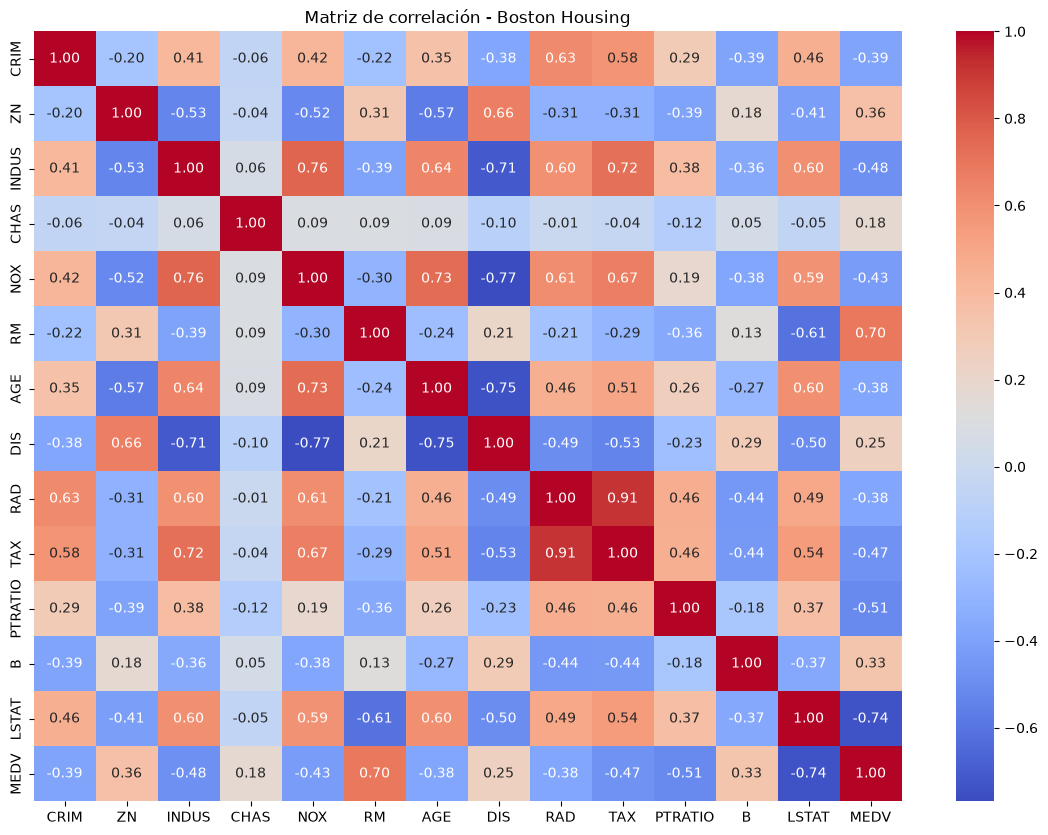

In [19]:
plt.figure(figsize=(14, 10))

sns.heatmap(boston_housing.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Matriz de correlación - Boston Housing")
plt.show()

### Draw 2 scatter plots to see the relationship between **MEDV** and **LSTAT** and **RM**

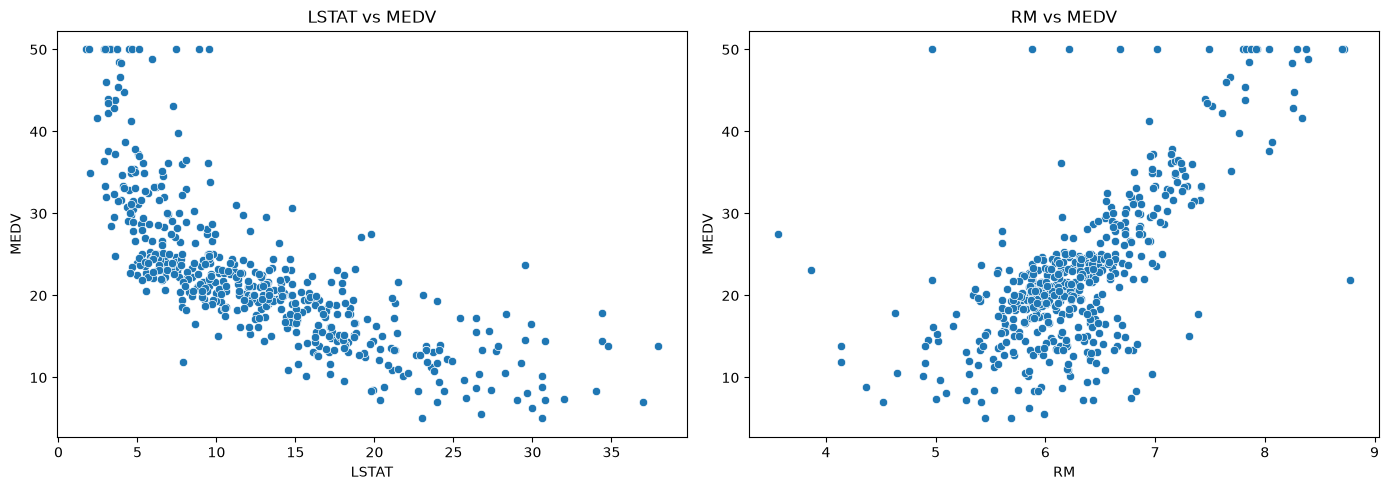

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# LSTAT vs MEDV
sns.scatterplot(data=boston_housing, x="LSTAT", y="MEDV", ax=ax[0])
ax[0].set_title("LSTAT vs MEDV")

# RM vs MEDV
sns.scatterplot(data=boston_housing, x="RM", y="MEDV", ax=ax[1])
ax[1].set_title("RM vs MEDV")

plt.tight_layout()
plt.show()

**Prepare the data for training**
Create a dataframe X including **LSTAT** and **RM** columns.
Y should be a pandas series including target values **'MEDV'**


In [24]:
X = boston_housing[["LSTAT", "RM"]]
y = boston_housing["MEDV"]

In [25]:
X.head()

,LSTAT,RM
0,4.98,6.575
1,9.14,6.421
2,4.03,7.185
3,2.94,6.998
4,5.33,7.147


In [26]:
y.head()

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

**Split the data into training and testing sets**

Splits the training and test data set in 80% : 20%. Assign random_state to any value. This ensures consistency. Print the sahes of the resulting objects

In [31]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# **Linear Regression**

Build a linear regression model with sklearn LinearRegression.
We'll use Mean Squared error and R2 score to evaluate our model, so be sure to make the needed imports.

Import the necessary functions and train a LinearRegression model

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [33]:
model_train = LinearRegression()
model_train.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.63, 5.47]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['LSTAT','RM']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.841
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2


**Evaluate the model performance in the training and testing sets**

In [37]:
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [35]:
y_train_pred = model_train.predict(X_train)
y_test_pred = model_train.predict(X_test)

In [46]:
predictions = model_train.predict(X_train)

print("MAE:", mean_absolute_error(y_train, predictions))
print("MAPE:", mean_absolute_percentage_error(y_train, predictions))
print("MSE:", mean_squared_error(y_train, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_train, predictions)))
print("r2_score train:", model_train.score(X_train, y_train))

MAE: 3.940490223422214
MAPE: 0.2079867605631777
MSE: 30.39185519321462
RMSE: 5.512880843371696
r2_score train: 0.6501592679428922


In [48]:
predictions = model_train.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MAPE:", mean_absolute_percentage_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("r2_score train:", model_train.score(X_test, y_test))

MAE: 3.8987597213823597
MAPE: 0.2074364015370496
MSE: 31.243290601783634
RMSE: 5.5895698047151745
r2_score train: 0.5739577415025858


**Lets see the model performance visually. Let's plot y_test vs y_pred**

Plotting the y_test vs y_pred. Ideally should have been a straight line

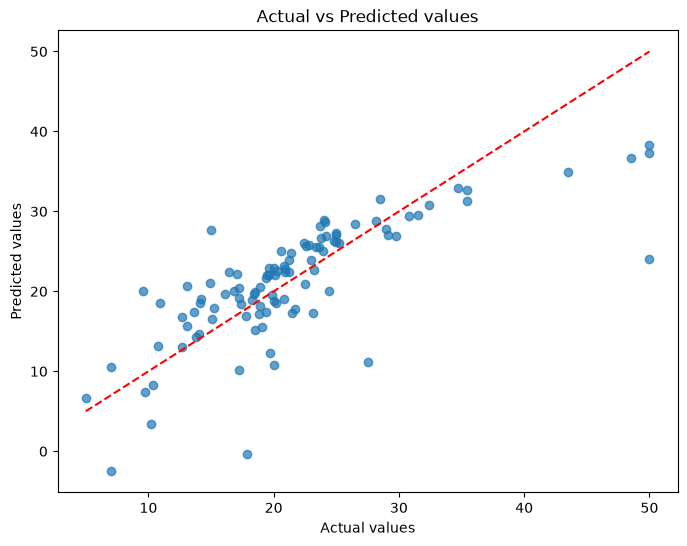

In [49]:
y_pred = model_train.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--")

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted values")
plt.show()

In [50]:
y_test.min()

np.float64(5.0)

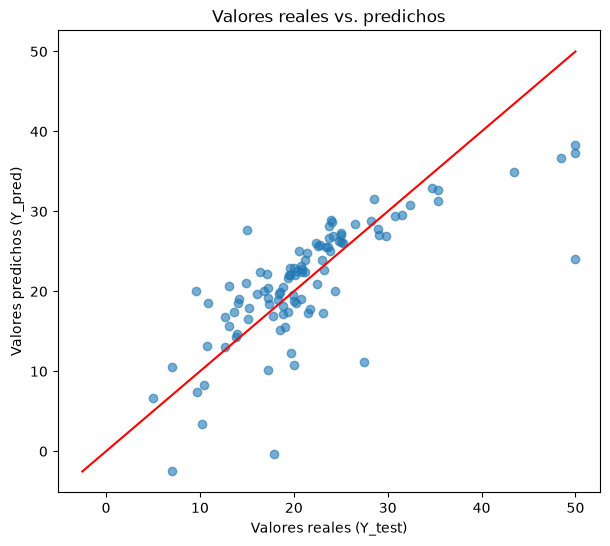

In [51]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.6)

limite_min = min(y_test.min(), y_test_pred.min())
limite_max = max(y_test.max(), y_test_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], 'r-')

plt.xlabel('Valores reales (Y_test)')
plt.ylabel('Valores predichos (Y_pred)')
plt.title('Valores reales vs. predichos')
plt.show()

# **Polynomial Regression**

We can see that **LSTAT** doesn't vary exactly in a linear way. Let's apply the Polynomial Regression with **degree 2** and test. 

To generate the higher order degrees, we use PolyniomialFeatures class from sklearn library. 

In [52]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [54]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [55]:
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0.11,-14.58, 0.01, -0.21, 1.64]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,60.18
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[4736.81, 302.06, 161.13, 10.55, 0.77]"


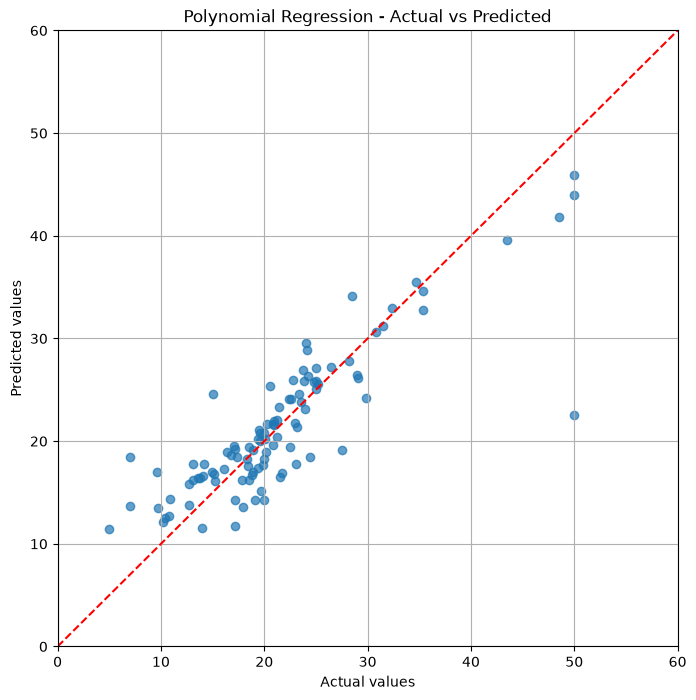

In [60]:
y_pred_poly = model_poly.predict(X_test_poly)

plt.figure(figsize=(8, 8))

plt.scatter(y_test, y_pred_poly, alpha=0.7)

plt.plot([0, 60], [0, 60], color="red", linestyle="--")

plt.xlim(0, 60)
plt.ylim(0, 60)

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Polynomial Regression - Actual vs Predicted")

plt.grid()
plt.show()

In [56]:
y_pred_poly = model_poly.predict(X_test_poly)

print("MAE:", mean_absolute_error(y_test, y_pred_poly))
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred_poly))
print("MSE:", mean_squared_error(y_test, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly)))
print("R2 train:", model_poly.score(X_train_poly, y_train))
print("R2 test:", model_poly.score(X_test_poly, y_test))

MAE: 2.8833469473606437
MAPE: 0.15958620425168382
MSE: 18.433777739112276
RMSE: 4.293457550635883
R2 train: 0.757615434471614
R2 test: 0.7486318454509269


In [57]:
print("R2 Linear:", model_train.score(X_test, y_test))
print("R2 Polynomial:", model_poly.score(X_test_poly, y_test))

R2 Linear: 0.5739577415025858
R2 Polynomial: 0.7486318454509269


**Did the model improve using the Polynomial model?**

In [58]:
print("Linear Regression:")
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", model_train.score(X_test, y_test))

print("\nPolynomial Regression:")
print("MSE:", mean_squared_error(y_test, y_pred_poly))
print("R2:", model_poly.score(X_test_poly, y_test))

Linear Regression:
MSE: 31.243290601783634
R2: 0.5739577415025858

Polynomial Regression:
MSE: 18.433777739112276
R2: 0.7486318454509269


In [ ]:
yes 

**Did the model improve using the Polynomial model with degree 3? Or more?**

In [59]:
for degree in range(1, 6):

    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model_poly = LinearRegression()
    model_poly.fit(X_train_poly, y_train)

    y_pred_poly = model_poly.predict(X_test_poly)

    print("Degree:", degree)
    print("MSE:", mean_squared_error(y_test, y_pred_poly))
    print("R2 train:", model_poly.score(X_train_poly, y_train))
    print("R2 test:", model_poly.score(X_test_poly, y_test))
    print("----------------------------")

Degree: 1
MSE: 31.243290601783627
R2 train: 0.6501592679428922
R2 test: 0.5739577415025858
----------------------------
Degree: 2
MSE: 18.433777739112276
R2 train: 0.757615434471614
R2 test: 0.7486318454509269
----------------------------
Degree: 3
MSE: 17.87980552751048
R2 train: 0.7597107128696179
R2 test: 0.7561859656357631
----------------------------
Degree: 4
MSE: 19.67690290271647
R2 train: 0.7710774503297558
R2 test: 0.7316802426557123
----------------------------
Degree: 5
MSE: 19.25005749533161
R2 train: 0.7628824982080289
R2 test: 0.7375008261438393
----------------------------


In [65]:
from sklearn.model_selection import cross_val_score

In [69]:
results_cv = cross_val_score(LinearRegression(), X, y, scoring="neg_mean_absolute_error", cv= 10)
print(results_cv)
print(results_cv.mean())
print(results_cv.std())

[-2.74282364 -2.66486168 -2.89248316 -5.15153202 -3.9402028  -4.64564316
 -3.82923301 -8.69643448 -6.53638215 -2.94554412]
-4.404514022690067
1.8528516111956592


In [ ]:
poly_reg = PolynomialFeatures(degree=2)
poly_reg.fit
X_poly = poly_reg.transform(X)

results_cv = cross_val_score(poly_reg_2, X_poly, y, scoring="neg_mean_absolute_error", cv=10)
print(results_cv)
print(results_cv.mean())
print(results_cv.std())

NotFittedError: This PolynomialFeatures instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.